In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8')

In [2]:
# === Plotting function (server-wide metric only) ===
def plot_server_metrics(val_pivot, test_metric, test_label, y_label, title):
    plt.figure(figsize=(10, 5))
    plt.plot(val_pivot.index, val_pivot[test_metric], label=test_label, marker='o', color='orange')
    plt.xlabel('Epoch')
    plt.ylabel(y_label)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


In [3]:
# === Plotting function ===
def plot_server_metrics(val_pivot, test_metric, test_label, y_label, title):
    plt.figure(figsize=(10, 5))
    plt.plot(val_pivot.index, val_pivot[test_metric], label=test_label, marker='o', color='orange')
    plt.xlabel('Epoch')
    plt.ylabel(y_label)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

In [4]:
def update_ema(
    prev_ema,
    current_value: float,
    smoothing_weight: float,
) -> float:
    """We use EMA to visually enhance the learning trend for each round.

    Parameters
    ----------
    prev_ema : float
        The list of metrics to aggregate.
    current_value : float
        The list of metrics to aggregate.
    smoothing_weight : float
        The list of metrics to aggregate.


    Returns
    -------
    EMA_Loss or EMA_ACC
        The weighted average metric.
    """
    if prev_ema is None:
        return current_value
    return (1 - smoothing_weight) * current_value + smoothing_weight * prev_ema

In [5]:
def compute_ema_series(values, smoothing_weight=0.95):
    ema_values = []
    prev_ema = None

    for v in values:
        prev_ema = update_ema(prev_ema, v, smoothing_weight)
        ema_values.append(prev_ema)

    return ema_values

In [6]:
def plot_flower(avg_acc, avg_loss, use_ema=False):
    """
    Plota múltiplos modelos no mesmo gráfico (accuracy + loss)

    Parameters
    ----------
    avg_acc : dict[str, pd.Series]
        nome_modelo -> série de acurácia (index = epoch)
    avg_loss : dict[str, pd.Series]
        nome_modelo -> série de loss (index = epoch)
    """

    if use_ema:
        smoothing_weight = 0.95

        avg_acc = {
            k: pd.Series(
                compute_ema_series(v, smoothing_weight),
                index=v.index
            )
            for k, v in avg_acc.items()
        }

        avg_loss = {
            k: pd.Series(
                compute_ema_series(v, smoothing_weight),
                index=v.index
            )
            for k, v in avg_loss.items()
        }

    plt.figure(figsize=(7, 12))

    # -------------------------
    # ACCURACY
    # -------------------------
    plt.subplot(2, 1, 1)

    for name, series in avg_acc.items():
        plt.plot(
            series.index.astype(int),
            series.values,
            linewidth=3,
            label=name,
        )

    plt.title("Accuracy")
    plt.ylabel("Acurácia")
    plt.grid(True)
    plt.legend()

    # -------------------------
    # LOSS
    # -------------------------
    plt.subplot(2, 1, 2)

    for name, series in avg_loss.items():
        plt.plot(
            series.index.astype(int),
            series.values,
            linewidth=3,
            label=name,
        )

    plt.title("Loss")
    plt.xlabel("Rodada")
    plt.ylabel("Loss")
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    plt.show()

In [7]:
files = {
    "./Personalized/FedMeta ProxyNCA V2/Results/WISDM/measures009A.csv": "Modelo Proposto",
    "./Federated/ProxyNCA/Results/WISDM/measures001A.csv": "FedMeta + ProxyNCA",
    #"./Personalized/FedMeta MobileNetV2/Results/WISDM/measures024A.csv": "FedMeta + MobileNetV2",
}

In [8]:
avg_loss = {}
avg_acc = {}

for path, name in files.items():
    df = pd.read_csv(path)
    df['validation'] = df['validation'].astype(bool)

    df_val = df[df['validation'] == True]

    users = sorted(df['user'].unique())

    all_losses = []
    all_accs = []

    for user in users:
        user_df = df_val[df_val['user'] == user]

        pivot = user_df.pivot(index='epoch', columns='metric', values='values')

        # -------- LOSS --------
        if "metrics.LOSS" in pivot.columns:
            loss = pd.to_numeric(pivot["metrics.LOSS"], errors="coerce")
            loss.index = pd.to_numeric(pivot.index, errors="coerce")
            loss = loss[~loss.index.isna()]

            if not loss.empty:
                loss.name = user
                all_losses.append(loss)

        # -------- ACC --------
        if "metrics.TEST_ACC" in pivot.columns:
            acc = pd.to_numeric(pivot["metrics.TEST_ACC"], errors="coerce")
            acc.index = pd.to_numeric(pivot.index, errors="coerce")
            acc = acc[~acc.index.isna()]

            if not acc.empty:
                acc.name = user
                all_accs.append(acc)

    # -------- média por arquivo --------
    if all_losses:
        df_loss = pd.concat(all_losses, axis=1).sort_index()
        avg_loss[name] = df_loss.mean(axis=1, skipna=True)

    if all_accs:
        df_acc = pd.concat(all_accs, axis=1).sort_index()
        avg_acc[name] = df_acc.mean(axis=1, skipna=True)

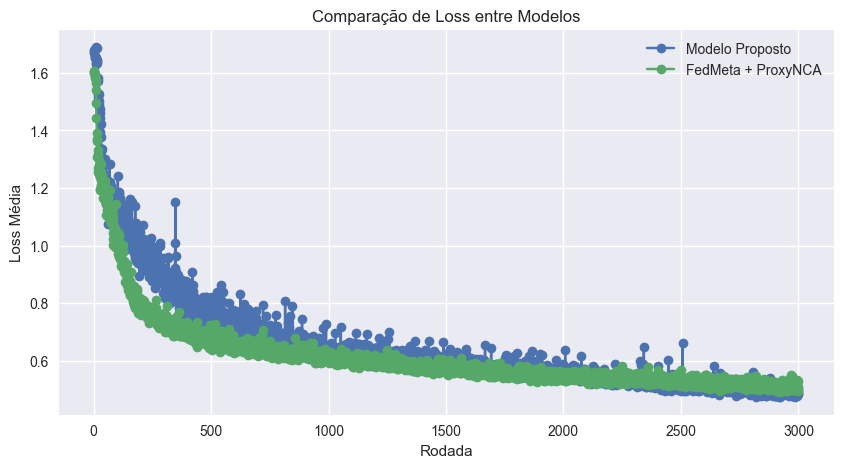

In [9]:
plt.figure(figsize=(10, 5))

for name, series in avg_loss.items():
    plt.plot(series.index.astype(int), series.values,
             marker='o', label=name)

plt.xlabel('Rodada')
plt.ylabel('Loss Média')
plt.title('Comparação de Loss entre Modelos')
plt.legend()
plt.grid(True)
plt.show()

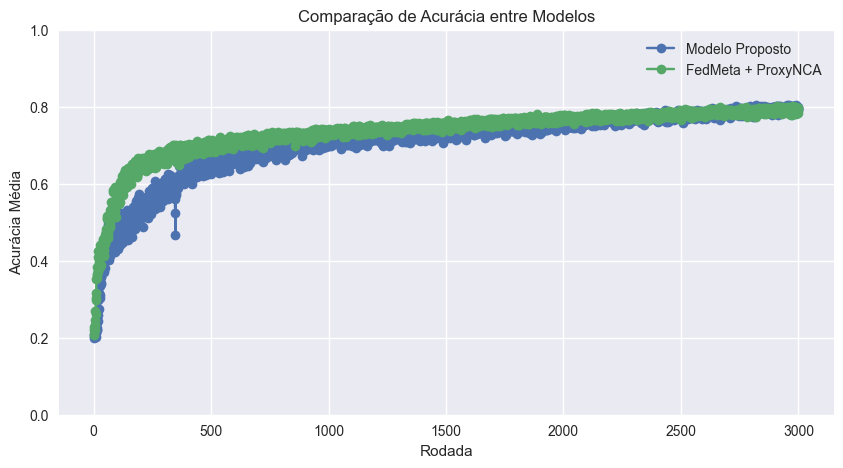

In [10]:
plt.figure(figsize=(10, 5))

for name, series in avg_acc.items():
    plt.plot(series.index.astype(int), series.values,
             marker='o', label=name)

plt.xlabel('Rodada')
plt.ylabel('Acurácia Média')
plt.ylim(0, 1)
plt.title('Comparação de Acurácia entre Modelos')
plt.legend()
plt.grid(True)
plt.show()

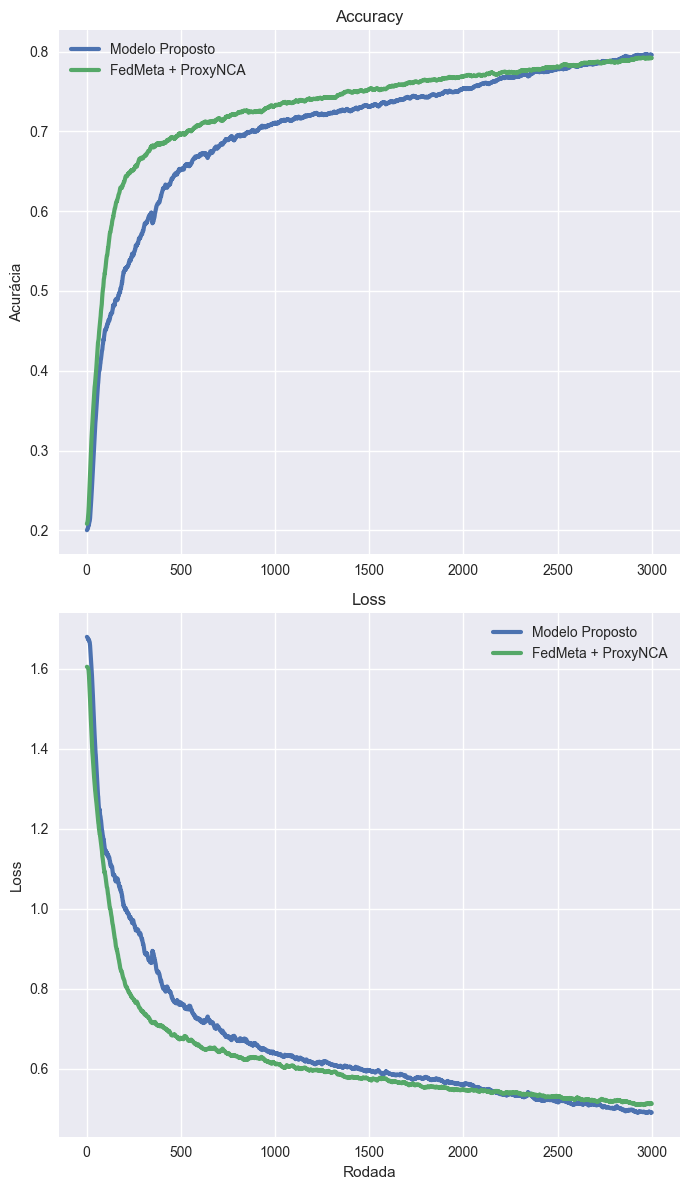

In [11]:
plot_flower(avg_acc, avg_loss, use_ema=True)